# Garden: profit outlook and which lever matters

**Question:** looking forward rather than back, how much gross profit can Garden expect in July to December 2026, and how much would each lever add: closing the cost gap, matching Harbour's prices, or the discount review?

**Context from the team's work:**
- The root-cause report splits the Harbour–Garden gap of $281.54 a day into transaction count (52%), unit costs (38%) and prices (12%), and sizes the six-month cost gap at about $15,900.
- `10_data_fingerprints.ipynb` shows that Garden's cost is exactly Harbour's x 1.43 and its price exactly Harbour's / 1.05, on every product. Both gaps are **formulas**, so how much of the cost gap is avoidable cash is unknown and could be zero.

This notebook does not settle that question. It shows how much each answer is worth, so Stories knows how much the finance check matters.

Throughout, **observed facts** are kept separate from **assumptions** (marked *Assumption*) and **estimates** (marked *Estimate*). All money is gross profit (revenue minus recorded product cost), before labour, rent and other overhead.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import chi2_contingency

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
# Repository layout: run from the repo root or notebooks/; data comes from STORIES_DATA or data/
ROOT = Path.cwd()
if not (ROOT / "reports").exists(): ROOT = ROOT.parent
DATA = Path(os.environ.get("STORIES_DATA", ROOT / "data" / "stories_transactions.csv"))
FIG = ROOT / "figures" / "garden_outlook"; FIG.mkdir(parents=True, exist_ok=True)

BRANCH_COLORS = {"Harbour": "#2a78d6", "Garden": "#eb6834", "Uptown": "#1baf7a"}
BRANCHES = list(BRANCH_COLORS)
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titleweight": "bold", "axes.titlesize": 11, "axes.titlelocation": "left",
    "font.size": 9, "legend.frameon": False, "lines.linewidth": 2,
})
def save(fig, name):
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight", dpi=150)

## 1. Load the data

Same cleaning as `01_eda.ipynb` (132 exact duplicate rows removed; the root-cause report keeps them, which changes the six-month cost gap from $15,923 to $15,887).

In [2]:
raw = pd.read_csv(DATA, dtype={"Customer ID": "string"})
raw = raw.rename(columns={
    "Transaction ID": "txn", "Date": "date", "Time": "time", "Branch": "branch",
    "Customer ID": "cust", "Order Type": "order_type", "Product": "product",
    "Category": "category", "Quantity": "qty", "Unit Price (USD)": "price",
    "Discount Rate": "disc", "Unit Cost (USD)": "cost",
    "Line Revenue (USD)": "rev", "Line Gross Profit (USD)": "gp"})
raw = raw[~raw.duplicated()].copy()
raw["ts"] = pd.to_datetime(raw["date"] + " " + raw["time"])
raw["date"] = pd.to_datetime(raw["date"])
raw["hour"] = raw.ts.dt.hour
txn = raw.groupby("txn").agg(branch=("branch", "first"), date=("date", "first"), hour=("hour", "first"),
                             rev=("rev", "sum"), gp=("gp", "sum"))
txn["cats"] = raw.groupby("txn").category.apply(set)
g_lines = raw[raw.branch == "Garden"]
g_day = txn[txn.branch == "Garden"].groupby("date").agg(n=("gp", "size"), rev=("rev", "sum"), gp=("gp", "sum")).reset_index()
print("Garden: transactions", len(txn[txn.branch == "Garden"]), "| revenue $", round(g_day.rev.sum()), "| gross profit $", round(g_day.gp.sum()))

Garden: transactions 11163 | revenue $ 99531 | gross profit $ 46696


## 2. Is Garden's transaction gap concentrated anywhere?

Transaction count is the largest part of the gap (52%). If Garden were weak at particular hours or days, that would point to something fixable locally (opening hours, staffing, a competitor's lunch offer). If its traffic is the same fraction of Harbour's at all times, the gap is about size or location, and no time-targeted action will close it.

In [3]:
gh = txn[txn.branch.isin(["Garden", "Harbour"])]
ratio = {}
for name, key in [("hour", gh.hour), ("weekday", gh.date.dt.dayofweek), ("month", gh.date.dt.to_period("M"))]:
    tab = gh.groupby([key, "branch"]).size().unstack()
    ratio[name] = tab.Garden / tab.Harbour
    p = chi2_contingency(tab.values)[1]
    print(f"Garden / Harbour transactions by {name}: {ratio[name].min():.3f} to {ratio[name].max():.3f} | differs by {name}? p = {p:.2f}")

Garden / Harbour transactions by hour: 0.634 to 0.752 | differs by hour? p = 0.87
Garden / Harbour transactions by weekday: 0.663 to 0.705 | differs by weekday? p = 0.87
Garden / Harbour transactions by month: 0.665 to 0.711 | differs by month? p = 0.78


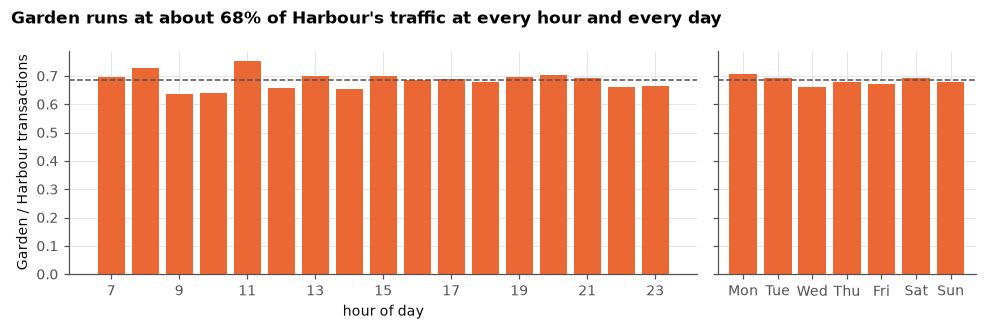

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(9.0, 3.0), sharey=True, gridspec_kw={"width_ratios": [17, 7]})
axes[0].bar(ratio["hour"].index, ratio["hour"].values, color="#eb6834")
axes[0].set_xlabel("hour of day"); axes[0].set_xticks(range(7, 24, 2))
axes[1].bar(range(7), ratio["weekday"].values, color="#eb6834")
axes[1].set_xticks(range(7), ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
for ax in axes:
    ax.axhline(ratio["hour"].mean(), color=MUTED, lw=1, ls="--")
axes[0].set_ylabel("Garden / Harbour transactions")
fig.suptitle("Garden runs at about 68% of Harbour's traffic at every hour and every day", x=0.01, ha="left",
             fontweight="bold", fontsize=11)
fig.tight_layout(); save(fig, "13_garden_traffic_ratio"); plt.show()

**Observed:** Garden's traffic is about 68% of Harbour's at every hour, weekday and month, and the differences are not statistically significant.

**Interpretation:** the transaction part of the gap is a uniform difference in scale, not a weak slot. It cannot be closed by changing hours or targeting a time of day, and the data has no footfall to say why Garden is smaller. It is left out of the levers below.

## 3. Are Garden's unit economics stable?

In [5]:
gm = g_lines.groupby(g_lines.date.dt.to_period("M")).agg(transactions=("txn", "nunique"), rev=("rev", "sum"), gp=("gp", "sum"))
gm["gp_per_transaction"] = gm.gp / gm.transactions
gm["margin"] = gm.gp / gm.rev
gm.round(3)

,transactions,rev,gp,gp_per_transaction,margin
date,,,,,
2026-01,1497,13472.98,6318.25,4.221,0.469
2026-02,1557,13762.40,6421.83,4.124,0.467
2026-03,1843,16684.66,7867.79,4.269,0.472
2026-04,1887,16877.83,7888.90,4.181,0.467
2026-05,2128,18644.22,8805.55,4.138,0.472
2026-06,2251,20088.46,9393.84,4.173,0.468


**Observed:** gross profit per transaction stays between about $4.12 and $4.27 every month, and the margin between 46.7% and 47.2%. Growth comes only from more transactions. So a Garden profit forecast can be built as **transactions forecast x a stable profit per transaction**.

## 4. Forecast Garden's gross profit

**Model:** daily transactions follow a straight-line trend on log weekly totals with a fixed weekday profile (the trend model tested in `06_bundle_offers.ipynb`), multiplied by the average gross profit per transaction.

**Test on unseen months:** fit on 1 Jan to 30 Apr, forecast 1 May to 30 Jun, and compare with two simple baselines: the Jan to Apr average day, and the last four weeks of April repeated.

In [6]:
def fit_trend(d):
    t0 = d.date.min()
    w = d.assign(week=(d.date - t0).dt.days // 7).groupby("week").n.agg(["sum", "size"])
    w = w[w["size"] == 7]
    slope = np.polyfit(w.index, np.log(w["sum"]), 1)[0]
    wk = (d.date - t0).dt.days / 7
    prof = (d.n / np.exp(slope * wk)).groupby(d.date.dt.dayofweek).mean()
    return (lambda dates: prof.reindex(dates.dt.dayofweek).values * np.exp(slope * (dates - t0).dt.days / 7)), slope, prof

F_SPLIT = pd.Timestamp("2026-05-01")
trn, tst = g_day[g_day.date < F_SPLIT], g_day[g_day.date >= F_SPLIT].copy()
f, slope, _ = fit_trend(trn)
gp_tx = trn.gp.sum() / trn.n.sum()
tst["trend"] = f(tst.date) * gp_tx
tst["avg_day"] = trn.gp.mean()
last4 = trn[trn.date >= F_SPLIT - pd.Timedelta(days=28)]
tst["last_4_weeks"] = tst.date.dt.dayofweek.map(last4.groupby(last4.date.dt.dayofweek).gp.mean())

def wape(y, f): return (y - f).abs().sum() / y.sum()
res = pd.DataFrame({m: {"daily WAPE": wape(tst.gp, tst[m]), "two-month total error": tst[m].sum() / tst.gp.sum() - 1}
                    for m in ["trend", "last_4_weeks", "avg_day"]}).T
print(f"weekly growth (Jan-Apr fit): {np.expm1(slope):.2%} | gross profit per transaction: ${gp_tx:.2f}")
res.round(3)

weekly growth (Jan-Apr fit): 1.83% | gross profit per transaction: $4.20


,daily WAPE,two-month total error
trend,0.100,0.004
last_4_weeks,0.148,-0.120
avg_day,0.252,-0.204


**Observed:** the trend model forecasts Garden's daily gross profit on unseen months more accurately than both baselines, and its two-month total is close to the actual. The baselines under-forecast because they cannot follow the growth.

Now the outlook for **1 July to 31 December 2026**, refitted on all six months, under two growth assumptions:

- **Growth continues** (*Assumption*): the January to June trend carries on for six more months. This compounds to a large increase and is the optimistic case.
- **Growth stops** (*Assumption*): traffic stays at June's level with the same weekday pattern.

The truth is probably in between; the gap between the two is the main forecast uncertainty.

In [7]:
H2 = pd.Series(pd.date_range("2026-07-01", "2026-12-31"))
f_all, slope_all, prof_all = fit_trend(g_day)
gp_tx_all = g_day.gp.sum() / g_day.n.sum()
rev_tx_all = g_day.rev.sum() / g_day.n.sum()
june = g_day[g_day.date >= "2026-06-01"]
june_level = june.n.mean() / prof_all.reindex(june.date.dt.dayofweek).mean()
SCEN = {"growth continues": np.asarray(f_all(H2)), "growth stops": prof_all.reindex(H2.dt.dayofweek).values * june_level}
h2 = pd.DataFrame({s: {"transactions": v.sum(), "revenue": v.sum() * rev_tx_all, "gross_profit": v.sum() * gp_tx_all}
                   for s, v in SCEN.items()}).T
h1 = pd.Series({"transactions": g_day.n.sum(), "revenue": g_day.rev.sum(), "gross_profit": g_day.gp.sum()}, name="Jan-Jun actual")
print(f"weekly growth (Jan-Jun fit): {np.expm1(slope_all):.2%}")
print("Estimate, Garden July-December 2026:")
pd.concat([h1.to_frame().T, h2]).round(0)

weekly growth (Jan-Jun fit): 1.89%
Estimate, Garden July-December 2026:


,transactions,revenue,gross_profit
Jan-Jun actual,11163.0,99531.0,46696.0
growth continues,18490.0,164862.0,77347.0
growth stops,13583.0,121103.0,56817.0


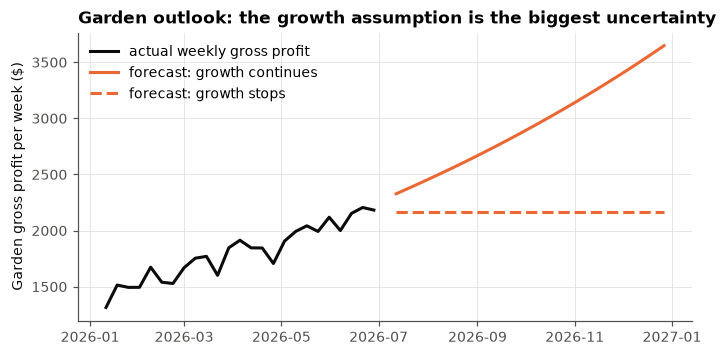

In [8]:
fig, ax = plt.subplots(figsize=(7.2, 3.4))
wk = g_day.set_index("date").gp.resample("W").sum()
ax.plot(wk.index[1:-1], wk.values[1:-1], color=INK, label="actual weekly gross profit")
for (s, v), ls in zip(SCEN.items(), ["-", "--"]):
    fw = pd.Series(v * gp_tx_all, index=H2.values).resample("W").sum()
    ax.plot(fw.index[1:-1], fw.values[1:-1], color="#eb6834", ls=ls, label=f"forecast: {s}")
ax.set_ylabel("Garden gross profit per week ($)")
ax.set_title("Garden outlook: the growth assumption is the biggest uncertainty")
ax.legend(loc="upper left"); save(fig, "14_garden_gp_outlook"); plt.show()

## 5. What is each lever worth from July to December?

Each lever is valued against the forecast above, for both growth cases. They are separate scenarios with different assumptions.

- **Cost gap:** Garden's unit cost is Harbour's x 1.43. *Assumption:* a share `f` of the extra 43% is avoidable cash. `10_data_fingerprints.ipynb` shows the gap is a formula, so `f` could be anywhere from 0 (pure allocation of rent or overhead) to 100%.
- **Prices:** Garden's prices are Harbour's / 1.05. Matching Harbour raises revenue by 5% at the same volume. *Assumption:* a share `L` of transactions is lost, spread evenly. Break-even `L` is where the extra margin is exactly cancelled.
- **Discount review:** the team's 153 low-margin Garden discount lines ($121.63 of discount over six months), scaled to the forecast traffic. This is the maximum, if every discount were removed and nobody left.

In [9]:
cost_gap_per_tx = (g_lines.qty * (g_lines.cost - g_lines.cost / 1.43)).sum() / g_day.n.sum()
DISC_REVIEW_6M = 121.63
print(f"Observed: extra cost per Garden transaction from the 1.43 multiplier: ${cost_gap_per_tx:.2f}")
rows = []
for s, r_ in h2.iterrows():
    scale = r_.transactions / g_day.n.sum()
    for f_ in [0.0, 0.10, 0.25, 0.50, 1.0]:
        rows.append(dict(growth=s, lever="cost gap", assumption=f"{f_:.0%} of the extra cost is avoidable",
                         gp_change=f_ * cost_gap_per_tx * r_.transactions))
    be = 0.05 * r_.revenue / (r_.gross_profit + 0.05 * r_.revenue)
    for L in [0.0, 0.05, be, 0.15]:
        rows.append(dict(growth=s, lever="match Harbour prices",
                         assumption=f"{L:.1%} of transactions lost" + (" (break-even)" if L == be else ""),
                         gp_change=(1 - L) * (r_.gross_profit + 0.05 * r_.revenue) - r_.gross_profit))
    rows.append(dict(growth=s, lever="discount review", assumption="all 153-line discounts removed, no customers lost",
                     gp_change=DISC_REVIEW_6M * scale))
lev = pd.DataFrame(rows)
lev.pivot_table(index=["lever", "assumption"], columns="growth", values="gp_change", sort=False).round(0)

Observed: extra cost per Garden transaction from the 1.43 multiplier: $1.42


growth                                                                  growth continues  growth stops
lever                assumption                                                                       
cost gap             0% of the extra cost is avoidable                               0.0           0.0
                     10% of the extra cost is avoidable                           2632.0        1933.0
                     25% of the extra cost is avoidable                           6579.0        4833.0
                     50% of the extra cost is avoidable                          13158.0        9665.0
                     100% of the extra cost is avoidable                         26316.0       19331.0
match Harbour prices 0.0% of transactions lost                                    8243.0        6055.0
                     5.0% of transactions lost                                    3964.0        2912.0
                     9.6% of transactions lost (break-even)                          0.0          -0.0
                     15.0% of transactions lost                                  -4595.0       -3376.0
discount review      all 153-line discounts removed, no customers lost             201.0         148.0

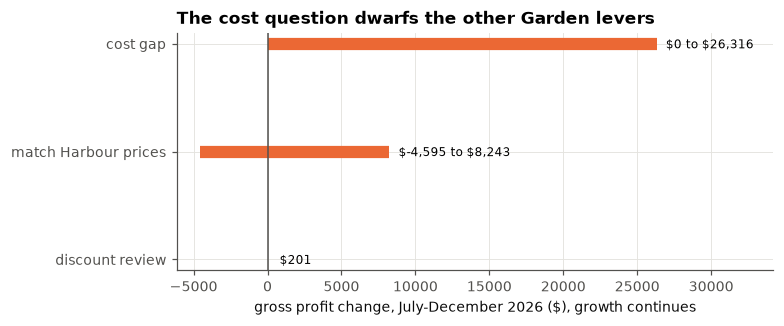

In [10]:
fig, ax = plt.subplots(figsize=(7.0, 2.8))
cont = lev[lev.growth == "growth continues"]
order = ["cost gap", "match Harbour prices", "discount review"]
for i, name in enumerate(order):
    v = cont[cont.lever == name].gp_change
    ax.plot([v.min(), v.max()], [i, i], color="#eb6834", lw=8, solid_capstyle="butt")
    label = f"\${v.max():,.0f}" if v.min() == v.max() else f"\${v.min():,.0f} to \${v.max():,.0f}"
    ax.annotate(label, (v.max(), i), xytext=(6, -3), textcoords="offset points", fontsize=8)
ax.axvline(0, color=MUTED, lw=1)
ax.set_yticks(range(len(order)), order); ax.invert_yaxis()
ax.set_xlabel("gross profit change, July-December 2026 ($), growth continues")
ax.set_title("The cost question dwarfs the other Garden levers")
ax.set_xlim(right=cont.gp_change.max() * 1.3)
save(fig, "15_garden_lever_ranges"); plt.show()

## 6. How the cost answer changes Garden's offers

In `06_bundle_offers.ipynb`, Garden needs roughly twice the take-up of the other branches for a bundle to break even, because of its costs. If the 1.43 multiplier is an allocation rather than real cost, the right cost for offer decisions is Harbour-equivalent cost (Garden cost / 1.43). Break-even take-up for the two recommended bundles at 10% off, Apr to Jun baskets:

In [11]:
test = raw[raw.date >= "2026-04-01"]
test_tx = txn[(txn.date >= "2026-04-01") & (txn.branch == "Garden")]
g_test = test[test.branch == "Garden"]
D = 0.10
rows = []
for anchor, partner in [("Bakery", "Matcha & Tea"), ("Cold Drinks", "Sandwiches")]:
    has_a, has_b = test_tx.cats.map(lambda s: anchor in s), test_tx.cats.map(lambda s: partner in s)
    both, a_only, b_only = (has_a & has_b).sum(), (has_a & ~has_b).sum(), (~has_a & has_b).sum()
    for label, cost_scale in [("recorded Garden cost", 1.0), ("Harbour-equivalent cost (/1.43)", 1 / 1.43)]:
        u = {}
        for c in [anchor, partner]:
            l = g_test[g_test.category == c]
            u[c] = ((l.qty * l.price).sum() / l.qty.sum(), (l.qty * (l.price - l.cost * cost_scale)).sum() / l.qty.sum())
        P, G = u[anchor][0] + u[partner][0], u[anchor][1] + u[partner][1]
        cost = both * D * P
        upside = a_only * (G - D * P - u[anchor][1]) + b_only * (G - D * P - u[partner][1])
        rows.append(dict(bundle=f"{anchor} + {partner}", costs=label, bundle_margin=G / P, breakeven_takeup=cost / upside))
pd.DataFrame(rows).round(3)

,bundle,costs,bundle_margin,breakeven_takeup
0,Bakery + Matcha & Tea,recorded Garden cost,0.496,0.092
1,Bakery + Matcha & Tea,Harbour-equivalent cost (/1.43),0.648,0.061
2,Cold Drinks + Sandwiches,recorded Garden cost,0.400,0.054
3,Cold Drinks + Sandwiches,Harbour-equivalent cost (/1.43),0.580,0.028


**Observed:** with Harbour-equivalent costs, Garden's break-even take-up falls to roughly the level of the other branches. So the finance answer also decides whether Garden should be in the bundle pilot on equal terms.

## 7. Recommendation

**Estimate:** Garden should make about **$57,000 to $77,000** of gross profit from July to December 2026 (growth stops / growth continues), against $46,700 from January to June. The forecast was tested on May and June with a 10% daily error and a two-month total within 0.4%, against 15% and 25% for simple baselines.

**Which Garden lever matters (July to December, gross profit):**

| Lever | Value | What decides it |
|---|---|---|
| Cost gap (Garden cost = Harbour x 1.43) | **$0 to $26,000**; about $1,900 to $2,600 per 10% that is avoidable | What the 1.43 contains: allocation (≈ $0) or real cash |
| Match Harbour's prices (+5%) | up to $6,000 to $8,000 if no customers are lost; $0 if 9.6% are lost; about -$3,400 to -$4,600 if 15% are lost | How customers react to a 5% price rise (never observed) |
| Discount review (153 low-margin lines) | at most about $150 to $200 | Already small; keep it as a clean-up, not a headline |
| Transaction gap (Garden ≈ 68% of Harbour) | not valued | Uniform at every hour and day; needs footfall and location data |

**Recommended order:**
1. **Ask finance what the 1.43 is.** It is the only Garden question worth tens of thousands of dollars, and it costs nothing to ask. Because the multiplier is an exact formula (`10`), the answer is a definition, not an investigation of invoices product by product.
2. **If part of it is real cost,** target that part directly (supplier contract, transfer price or waste rule) and track Garden's cost per transaction monthly.
3. **If it is allocation,** use Harbour-equivalent costs for operating decisions. Garden's bundle break-even then falls from 9.2% and 5.4% to 6.1% and 2.8%, close to the other branches, so Garden can join the bundle pilot on equal terms.
4. **Test prices before changing them:** a 4-week, +5% price on one category at Garden, compared with the weeks before, measuring transactions lost against the 9.6% break-even.

## 8. What could change this

- **The cost gap may be allocation.** `10_data_fingerprints.ipynb` shows the 1.43 is an exact formula. If it allocates rent or overhead, the avoidable share is 0 and the cost lever is worth nothing in cash, although Garden's reported margin would still be misleading for decisions such as offers.
- **Growth may not continue.** The optimistic case compounds about 1.9% a week for six more months. The "growth stops" case is the conservative floor. If the growth pattern is a setting of the data (see 10), neither case describes the real business.
- **Customer response to prices is unknown.** Prices never change in the data. The break-even loss is a boundary, not a prediction.
- **Gross profit is not net profit.** Labour, rent, waste and implementation costs are not in the file.
- **The transaction gap is not addressed.** Garden is uniformly about 68% of Harbour's size; explaining that needs footfall and location data the file does not have.